## Claude

Experiment: KdV_TwoSoliton_PINN
Network architecture: [2, 50, 50, 50, 50, 1]
Training epochs: 50000
Learning rate: 0.001
Residual points: 10000
BC points: 200
IC points: 200
Reference solution shape: (256, 100)
Reference solution range: [0.0000, 2.9999]

Training data generated:
  IC points: 200
  BC1 points (x=0): 200
  BC2 points (x=20): 200
  BC3 points (Neumann x=20): 200
  Residual points: 10000

Network initialized with 5 layers

Starting Training


Training:   0%|          | 164/50000 [00:05<16:58, 48.95it/s] 


Epoch 0/50000
  Loss: 1.209425e+00
  Rel. L2: 9.778376e-01
  L2: 9.895464e+01
  L∞: 2.982522e+00


Training:  10%|█         | 5101/50000 [00:12<01:06, 678.42it/s]


Epoch 5000/50000
  Loss: 2.608148e-03
  Rel. L2: 2.718333e-01
  L2: 2.750883e+01
  L∞: 7.332681e-01


Training:  20%|██        | 10101/50000 [00:20<00:58, 678.40it/s]

... (13 outputs left out)

Training:  90%|█████████ | 45101/50000 [01:13<00:07, 678.03it/s]


Epoch 45000/50000
  Loss: 1.625317e-04
  Rel. L2: 1.484835e-02
  L2: 1.502615e+00
  L∞: 5.229998e-02


Training: 100%|██████████| 50000/50000 [01:21<00:00, 614.26it/s]



Training Complete!
Solution:
T shape: (256, 100), X shape: (256, 100), Exact0 shape: (256, 100), u shape: (256, 100)
Calculating PDE residuals for plotting...
Residuals calculated. Min: 2.384185791015625e-07, Max: 0.10095024108886719


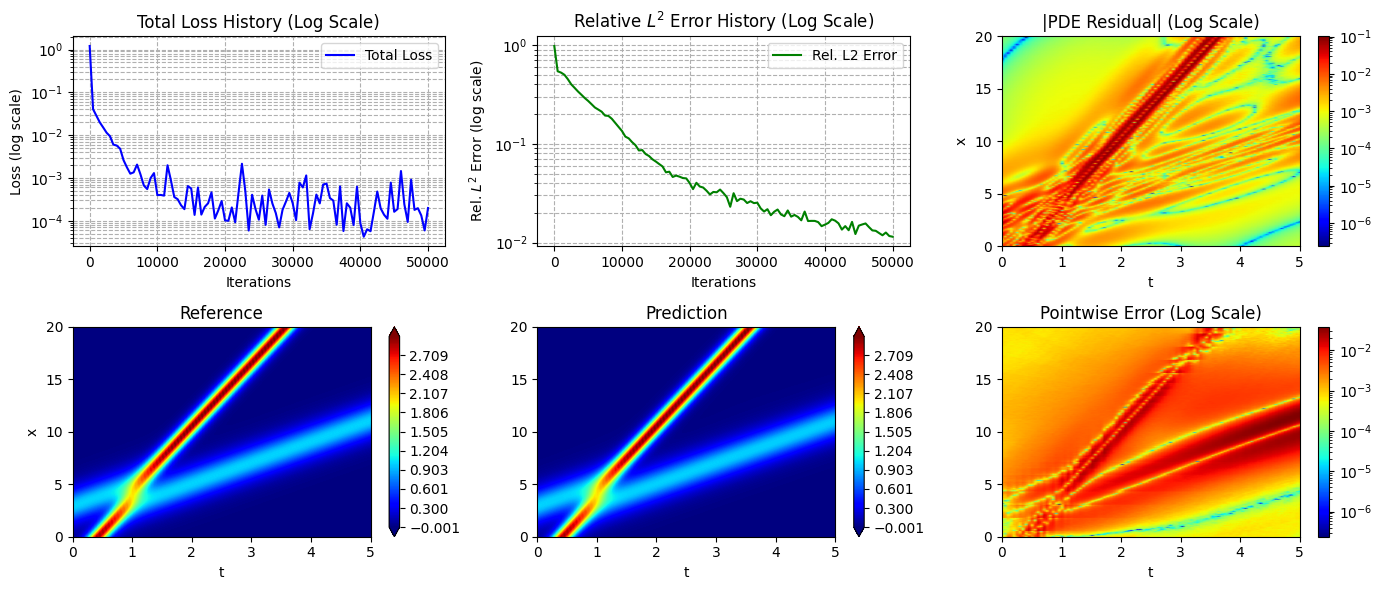


Minimum achieved RL2 error: 1.146907e-02

Results saved to KdV_TwoSoliton_PINN_results.mat


In [4]:
import jax
import jax.numpy as jnp
from jax import grad, vmap, jit
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors
import optax
from functools import partial
import argparse
from tqdm import tqdm
import scipy.io as sio

# Parse arguments
parser = argparse.ArgumentParser()
parser.add_argument('--Name', type=str, default='KdV_TwoSoliton_PINN')
parser.add_argument('--layers', type=int, nargs='+', default=[2, 50, 50, 50, 50, 1])
parser.add_argument('--epochs', type=int, default=50000)
parser.add_argument('--lr', type=float, default=1e-3)
parser.add_argument('--N_res', type=int, default=10000)
parser.add_argument('--N_bc', type=int, default=200)
parser.add_argument('--N_ic', type=int, default=200)
parser.add_argument('--seed', type=int, default=42)
args = parser.parse_args([])  # Empty list for notebook compatibility

print(f"Experiment: {args.Name}")
print(f"Network architecture: {args.layers}")
print(f"Training epochs: {args.epochs}")
print(f"Learning rate: {args.lr}")
print(f"Residual points: {args.N_res}")
print(f"BC points: {args.N_bc}")
print(f"IC points: {args.N_ic}")

# Set random seed
np.random.seed(args.seed)
key = jax.random.PRNGKey(args.seed)

# ============================================================================
# Analytical Solution: Two-Soliton KdV
# ============================================================================

def kdv_two_soliton(x, t, c1=6.0, c2=2.0, x1=-2.0, x2=2.0):
    """
    Two-soliton solution for KdV equation.
    
    Args:
        x: spatial coordinate (can be array)
        t: temporal coordinate (can be array)
        c1: velocity of first soliton
        c2: velocity of second soliton
        x1: initial position of first soliton
        x2: initial position of second soliton
    
    Returns:
        u: solution value
    """
    zeta1 = x - c1 * t - x1
    zeta2 = x - c2 * t - x2
    
    sqrt_c1 = jnp.sqrt(c1)
    sqrt_c2 = jnp.sqrt(c2)
    
    # Numerator
    term1 = c1 * jnp.cosh(sqrt_c2 * zeta2 / 2.0)**2
    term2 = c2 * jnp.sinh(sqrt_c1 * zeta1 / 2.0)**2
    numerator = 2.0 * (c1 - c2) * (term1 + term2)
    
    # Denominator
    cosh_sum = jnp.cosh((sqrt_c1 * zeta1 + sqrt_c2 * zeta2) / 2.0)
    cosh_diff = jnp.cosh((sqrt_c1 * zeta1 - sqrt_c2 * zeta2) / 2.0)
    denominator = ((sqrt_c1 - sqrt_c2) * cosh_sum + (sqrt_c1 + sqrt_c2) * cosh_diff)**2
    
    return numerator / denominator

# Vectorize for efficient evaluation
kdv_two_soliton_vec = vmap(vmap(kdv_two_soliton, in_axes=(0, None)), in_axes=(None, 0))

# ============================================================================
# Domain and Boundary Conditions
# ============================================================================

# Domain bounds
t_min, t_max = 0.0, 5.0
x_min, x_max = 0.0, 20.0

# Generate reference solution for visualization
Nx_ref, Nt_ref = 256, 100
x0 = np.linspace(x_min, x_max, Nx_ref)
t0 = np.linspace(t_min, t_max, Nt_ref)
T0, X0 = np.meshgrid(t0, x0)
Exact0 = np.array(kdv_two_soliton_vec(x0, t0)).T

print(f"Reference solution shape: {Exact0.shape}")
print(f"Reference solution range: [{Exact0.min():.4f}, {Exact0.max():.4f}]")

# ============================================================================
# Generate Training Data
# ============================================================================

# Initial condition: u(0, x) = g_0(x)
key, subkey = jax.random.split(key)
x_ic = jax.random.uniform(subkey, (args.N_ic, 1), minval=x_min, maxval=x_max)
t_ic = jnp.zeros_like(x_ic)
u_ic = kdv_two_soliton(x_ic, t_ic).reshape(-1, 1)

# Boundary condition at x=0: u(t, 0) = g_1(t)
key, subkey = jax.random.split(key)
t_bc1 = jax.random.uniform(subkey, (args.N_bc, 1), minval=t_min, maxval=t_max)
x_bc1 = jnp.zeros_like(t_bc1)
u_bc1 = kdv_two_soliton(x_bc1, t_bc1).reshape(-1, 1)

# Boundary condition at x=20: u(t, 20) = g_2(t)
key, subkey = jax.random.split(key)
t_bc2 = jax.random.uniform(subkey, (args.N_bc, 1), minval=t_min, maxval=t_max)
x_bc2 = jnp.full_like(t_bc2, x_max)
u_bc2 = kdv_two_soliton(x_bc2, t_bc2).reshape(-1, 1)

# Neumann boundary condition at x=20: u_x(t, 20) = g_3(t)
# Compute derivative analytically using JAX
du_dx_fn = jit(grad(lambda x, t: kdv_two_soliton(x, t).sum(), argnums=0))
key, subkey = jax.random.split(key)
t_bc3 = jax.random.uniform(subkey, (args.N_bc, 1), minval=t_min, maxval=t_max)
x_bc3 = jnp.full_like(t_bc3, x_max)
u_bc3 = jnp.array([du_dx_fn(x_bc3[i, 0], t_bc3[i, 0]) for i in range(args.N_bc)]).reshape(-1, 1)

# Collocation points for PDE residual
key, subkey = jax.random.split(key)
t_res = jax.random.uniform(subkey, (args.N_res, 1), minval=t_min, maxval=t_max)
key, subkey = jax.random.split(key)
x_res = jax.random.uniform(subkey, (args.N_res, 1), minval=x_min, maxval=x_max)

print(f"\nTraining data generated:")
print(f"  IC points: {x_ic.shape[0]}")
print(f"  BC1 points (x=0): {x_bc1.shape[0]}")
print(f"  BC2 points (x=20): {x_bc2.shape[0]}")
print(f"  BC3 points (Neumann x=20): {x_bc3.shape[0]}")
print(f"  Residual points: {t_res.shape[0]}")

# ============================================================================
# Neural Network Architecture
# ============================================================================

def init_network(layers, key):
    """Initialize MLP parameters."""
    params = []
    keys = jax.random.split(key, len(layers) - 1)
    
    for i in range(len(layers) - 1):
        key_w, key_b = jax.random.split(keys[i])
        
        # Xavier/Glorot initialization
        std = jnp.sqrt(2.0 / (layers[i] + layers[i + 1]))
        w = std * jax.random.normal(key_w, (layers[i], layers[i + 1]))
        b = jnp.zeros((layers[i + 1],))
        
        params.append({'w': w, 'b': b})
    
    return params

def forward(params, t, x):
    """Forward pass through MLP."""
    # Input normalization
    t_norm = 2.0 * (t - t_min) / (t_max - t_min) - 1.0
    x_norm = 2.0 * (x - x_min) / (x_max - x_min) - 1.0
    
    inputs = jnp.concatenate([t_norm, x_norm], axis=-1)
    
    # Hidden layers with tanh activation
    for i in range(len(params) - 1):
        inputs = jnp.tanh(inputs @ params[i]['w'] + params[i]['b'])
    
    # Output layer (no activation)
    output = inputs @ params[-1]['w'] + params[-1]['b']
    
    return output

# Initialize network
key, subkey = jax.random.split(key)
params = init_network(args.layers, subkey)
print(f"\nNetwork initialized with {len(params)} layers")

# ============================================================================
# Physics-Informed Loss Functions
# ============================================================================

@jit
def net_u(params, t, x):
    """Network prediction for u."""
    return forward(params, t, x)

@jit
def net_du_dt(params, t, x):
    """Compute du/dt using automatic differentiation."""
    return grad(lambda t: net_u(params, t, x).sum())(t)

@jit
def net_du_dx(params, t, x):
    """Compute du/dx using automatic differentiation."""
    return grad(lambda x: net_u(params, t, x).sum())(x)

@jit
def net_d3u_dx3(params, t, x):
    """Compute d³u/dx³ using automatic differentiation."""
    def du_dx(x):
        return grad(lambda x: net_u(params, t, x).sum())(x)
    
    def d2u_dx2(x):
        return grad(lambda x: du_dx(x).sum())(x)
    
    return grad(lambda x: d2u_dx2(x).sum())(x)

@jit
def pde_residual_single(params, t, x):
    """Compute KdV PDE residual for a single point."""
    u = net_u(params, t, x)
    u_t = net_du_dt(params, t, x)
    u_x = net_du_dx(params, t, x)
    u_xxx = net_d3u_dx3(params, t, x)
    
    # KdV equation: u_t + 6*u*u_x + u_xxx = 0
    residual = u_t + 6.0 * u * u_x + u_xxx
    
    return residual

# Vectorize PDE residual computation
pde_residual_batch = vmap(pde_residual_single, in_axes=(None, 0, 0))

def PDE_residuals(params, t, x, apply_fn=None):
    """Wrapper for batch PDE residual computation."""
    return pde_residual_batch(params, t, x)

@jit
def compute_loss(params, t_ic, x_ic, u_ic, t_bc1, x_bc1, u_bc1, 
                 t_bc2, x_bc2, u_bc2, t_bc3, x_bc3, u_bc3, t_res, x_res):
    """Compute total PINN loss."""
    # Initial condition loss
    u_ic_pred = vmap(net_u, in_axes=(None, 0, 0))(params, t_ic, x_ic)
    loss_ic = jnp.mean((u_ic_pred - u_ic)**2)
    
    # Boundary condition loss at x=0
    u_bc1_pred = vmap(net_u, in_axes=(None, 0, 0))(params, t_bc1, x_bc1)
    loss_bc1 = jnp.mean((u_bc1_pred - u_bc1)**2)
    
    # Boundary condition loss at x=20
    u_bc2_pred = vmap(net_u, in_axes=(None, 0, 0))(params, t_bc2, x_bc2)
    loss_bc2 = jnp.mean((u_bc2_pred - u_bc2)**2)
    
    # Neumann boundary condition loss at x=20
    u_bc3_pred = vmap(net_du_dx, in_axes=(None, 0, 0))(params, t_bc3, x_bc3)
    loss_bc3 = jnp.mean((u_bc3_pred - u_bc3)**2)
    
    # PDE residual loss
    residuals = pde_residual_batch(params, t_res, x_res)
    loss_res = jnp.mean(residuals**2)
    
    # Total loss (equal weighting)
    loss_total = loss_ic + loss_bc1 + loss_bc2 + loss_bc3 + loss_res
    
    return loss_total, (loss_ic, loss_bc1, loss_bc2, loss_bc3, loss_res)

# ============================================================================
# Error Computation
# ============================================================================

@jit
def compute_relative_l2_error(params, t_test, x_test, u_test):
    """Compute relative L2 error."""
    u_pred = vmap(net_u, in_axes=(None, 0, 0))(params, t_test, x_test)
    error = jnp.linalg.norm(u_pred - u_test) / jnp.linalg.norm(u_test)
    return error

@jit
def compute_l2_error(params, t_test, x_test, u_test):
    """Compute L2 error."""
    u_pred = vmap(net_u, in_axes=(None, 0, 0))(params, t_test, x_test)
    error = jnp.linalg.norm(u_pred - u_test)
    return error

@jit
def compute_linf_error(params, t_test, x_test, u_test):
    """Compute L-infinity error."""
    u_pred = vmap(net_u, in_axes=(None, 0, 0))(params, t_test, x_test)
    error = jnp.max(jnp.abs(u_pred - u_test))
    return error

# Prepare test data
t_test = T0.flatten()[:, None]
x_test = X0.flatten()[:, None]
u_test = Exact0.flatten()[:, None]

# ============================================================================
# Training Setup
# ============================================================================

# Optimizer
optimizer = optax.adam(args.lr)
opt_state = optimizer.init(params)

# Training history
all_its = []
all_loss = []
all_errors = []
all_gamma = []  # Not used but included for compatibility
all_lamB = []   # Not used but included for compatibility
all_L_infty = []
all_L_2 = []

# JIT-compiled training step
@jit
def train_step(params, opt_state, t_ic, x_ic, u_ic, t_bc1, x_bc1, u_bc1,
               t_bc2, x_bc2, u_bc2, t_bc3, x_bc3, u_bc3, t_res, x_res):
    """Single training step."""
    loss_fn = lambda p: compute_loss(p, t_ic, x_ic, u_ic, t_bc1, x_bc1, u_bc1,
                                     t_bc2, x_bc2, u_bc2, t_bc3, x_bc3, u_bc3,
                                     t_res, x_res)[0]
    
    loss_val, grads = jax.value_and_grad(loss_fn)(params)
    updates, opt_state = optimizer.update(grads, opt_state)
    params = optax.apply_updates(params, updates)
    
    return params, opt_state, loss_val

# ============================================================================
# Training Loop
# ============================================================================

print("\n" + "="*70)
print("Starting Training")
print("="*70)

log_interval = max(1, args.epochs // 100)

for epoch in tqdm(range(args.epochs), desc="Training"):
    # Training step
    params, opt_state, loss_val = train_step(
        params, opt_state, t_ic, x_ic, u_ic,
        t_bc1, x_bc1, u_bc1, t_bc2, x_bc2, u_bc2,
        t_bc3, x_bc3, u_bc3, t_res, x_res
    )
    
    # Logging
    if epoch % log_interval == 0 or epoch == args.epochs - 1:
        rel_l2 = compute_relative_l2_error(params, t_test, x_test, u_test)
        l2 = compute_l2_error(params, t_test, x_test, u_test)
        linf = compute_linf_error(params, t_test, x_test, u_test)
        
        all_its.append(epoch)
        all_loss.append(float(loss_val))
        all_errors.append(float(rel_l2))
        all_gamma.append(0.0)  # Placeholder
        all_lamB.append(0.0)   # Placeholder
        all_L_2.append(float(l2))
        all_L_infty.append(float(linf))
        
        if epoch % (log_interval * 10) == 0:
            print(f"\nEpoch {epoch}/{args.epochs}")
            print(f"  Loss: {loss_val:.6e}")
            print(f"  Rel. L2: {rel_l2:.6e}")
            print(f"  L2: {l2:.6e}")
            print(f"  L∞: {linf:.6e}")

print("\n" + "="*70)
print("Training Complete!")
print("="*70)

# Convert to numpy for compatibility
all_its = np.array(all_its)
all_loss = np.array(all_loss)
all_errors = np.array(all_errors)
all_gamma = np.array(all_gamma)
all_lamB = np.array(all_lamB)
all_L_2 = np.array(all_L_2)
all_L_infty = np.array(all_L_infty)



# ============================================================================
# Final Visualization & Error Reporting
# ============================================================================

current_params_for_eval = params
apply_fn = net_u

# Create meshgrid with correct orientation
T, X = np.meshgrid(t0, x0)  # T and X have shape (Nx, Nt)
t = T.flatten()[:, None]
x = X.flatten()[:, None]
u_gt = Exact0.flatten()[:, None]

print('Solution:')
u = vmap(net_u, in_axes=(None, 0, 0))(current_params_for_eval, t, x)
u = np.array(u.reshape(T.shape))  # Reshape to match T.shape

# Verify shapes match
print(f"T shape: {T.shape}, X shape: {X.shape}, Exact0 shape: {Exact0.shape}, u shape: {u.shape}")

fig, axes = plt.subplots(2, 3, figsize=(14, 6))

# Top left: Total Loss History
ax_tl = axes[0, 0]
ax_tl.plot(all_its, all_loss, label='Total Loss', color='blue')
ax_tl.set_yscale('log')
ax_tl.set_title('Total Loss History (Log Scale)')
ax_tl.set_xlabel('Iterations')
ax_tl.set_ylabel('Loss (log scale)')
ax_tl.grid(True, which="both", ls="--")
ax_tl.legend()

# Top middle: Relative L2 Error History
ax_tm = axes[0, 1]
ax_tm.plot(all_its, all_errors, label='Rel. L2 Error', color='green')
ax_tm.set_yscale('log')
ax_tm.set_title('Relative $L^2$ Error History (Log Scale)')
ax_tm.set_xlabel('Iterations')
ax_tm.set_ylabel('Rel. $L^2$ Error (log scale)')
ax_tm.grid(True, which="both", ls="--")
ax_tm.legend()

# Top right: PDE Residuals
ax_tr = axes[0, 2]
print("Calculating PDE residuals for plotting...")
res = PDE_residuals(current_params_for_eval, t, x, apply_fn)
res_grid = np.abs(np.array(res.reshape(T.shape)))
print(f"Residuals calculated. Min: {res_grid.min()}, Max: {res_grid.max()}")
res_log_norm = colors.LogNorm(vmin=res_grid.min()+1e-16, vmax=res_grid.max() + 1e-16)
mesh_res = ax_tr.pcolormesh(T, X, res_grid, cmap='jet', norm=res_log_norm, shading='gouraud')
fig.colorbar(mesh_res, ax=ax_tr)
ax_tr.set_xlabel('t')
ax_tr.set_ylabel('x')
ax_tr.set_title('|PDE Residual| (Log Scale)')

# Shared colorbar limits for solution plots
global_vmin = min(np.min(u), np.min(Exact0))
global_vmax = max(np.max(u), np.max(Exact0))
shared_levels = np.linspace(global_vmin, global_vmax, 500)

# Bottom left: Reference Solution
ax_bl = axes[1, 0]
contour1 = ax_bl.contourf(T, X, Exact0, cmap='jet', levels=shared_levels, extend='both')
fig.colorbar(contour1, ax=ax_bl)
ax_bl.set_xlabel('t')
ax_bl.set_ylabel('x')
ax_bl.set_title('Reference')

# Bottom middle: Prediction
ax_bm = axes[1, 1]
contour2 = ax_bm.contourf(T, X, u, cmap='jet', levels=shared_levels, extend='both')
fig.colorbar(contour2, ax=ax_bm)
ax_bm.set_xlabel('t')
ax_bm.set_title('Prediction')

# Bottom right: Pointwise Error
ax_br = axes[1, 2]
error_data = np.abs(Exact0 - u)
err_log_norm = colors.LogNorm(vmin=error_data.min()+1e-16, vmax=error_data.max() + 1e-16)
mesh_err = ax_br.pcolormesh(T, X, error_data, cmap='jet', norm=err_log_norm, shading='gouraud')
fig.colorbar(mesh_err, ax=ax_br)
ax_br.set_xlabel('t')
ax_br.set_title('Pointwise Error (Log Scale)')

plt.tight_layout()
plt.savefig('summary_all.png', dpi=150)
plt.show()

print(f'\nMinimum achieved RL2 error: {np.nanmin(all_errors):.6e}')

# ============================================================================
# Save Experiment Results to .mat File
# ============================================================================

results_dict = {
    'model_name': args.Name,
    'all_errors': all_errors,
    'all_its': all_its,
    'all_loss': all_loss,
    'all_gamma': all_gamma,
    'all_lamB': all_lamB,
    'all_L_infty': all_L_infty,
    'all_L_2': all_L_2,
}

sio.savemat(f'{args.Name}_results.mat', results_dict)
print(f"\nResults saved to {args.Name}_results.mat")

## Gemini

In [6]:
import jax
import jax.numpy as jnp
from jax import grad, jit, vmap
from flax import linen as nn
import optax
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors

# Set random seed for reproducibility
key = jax.random.PRNGKey(42)

# ==========================================
# 1. Analytical Solution & Data Generation
# ==========================================

def get_exact_solution(t, x):
    """
    Computes the analytical two-soliton solution for KdV.
    """
    c1 = 6.0
    c2 = 2.0
    x1 = -2.0
    x2 = 2.0
    
    # Ensure inputs are arrays for broadcasting
    zeta1 = x - c1 * t - x1
    zeta2 = x - c2 * t - x2
    
    sqrt_c1 = jnp.sqrt(c1)
    sqrt_c2 = jnp.sqrt(c2)
    
    term1_num = c1 * jnp.cosh( (sqrt_c2 * zeta2) / 2.0 )**2
    term2_num = c2 * jnp.sinh( (sqrt_c1 * zeta1) / 2.0 )**2
    numerator = 2 * (c1 - c2) * (term1_num + term2_num)
    
    term1_den = (sqrt_c1 - sqrt_c2) * jnp.cosh( (sqrt_c1 * zeta1 + sqrt_c2 * zeta2) / 2.0 )
    term2_den = (sqrt_c1 + sqrt_c2) * jnp.cosh( (sqrt_c1 * zeta1 - sqrt_c2 * zeta2) / 2.0 )
    denominator = (term1_den + term2_den)**2
    
    return numerator / denominator

# Domain bounds
t_min, t_max = 0.0, 5.0
x_min, x_max = 0.0, 20.0

# Generate Training Data (Collocation Points)
N_f = 20000 
key, k1, k2 = jax.random.split(key, 3)
t_f = jax.random.uniform(k1, (N_f, 1), minval=t_min, maxval=t_max)
x_f = jax.random.uniform(k2, (N_f, 1), minval=x_min, maxval=x_max)

# Generate Boundary Data
N_b = 500 

# IC: t=0
key, k1 = jax.random.split(key, 2)
x_ic = jax.random.uniform(k1, (N_b, 1), minval=x_min, maxval=x_max)
t_ic = jnp.zeros_like(x_ic)
u_ic = get_exact_solution(t_ic, x_ic)

# BC1: x=0
key, k1 = jax.random.split(key, 2)
t_bc1 = jax.random.uniform(k1, (N_b, 1), minval=t_min, maxval=t_max)
x_bc1 = jnp.zeros_like(t_bc1)
u_bc1 = get_exact_solution(t_bc1, x_bc1)

# BC2: x=20 (Dirichlet + Neumann)
key, k1 = jax.random.split(key, 2)
t_bc2 = jax.random.uniform(k1, (N_b, 1), minval=t_min, maxval=t_max)
x_bc2 = jnp.full_like(t_bc2, x_max)
u_bc2 = get_exact_solution(t_bc2, x_bc2)

# Calculate exact derivative for Neumann BC at x=20
# vmap + grad allows us to get element-wise derivatives of the exact solution
u_x_exact_fn = vmap(grad(get_exact_solution, argnums=1))
u_x_bc2 = u_x_exact_fn(t_bc2.flatten(), x_bc2.flatten()).reshape(-1, 1)

data = {
    'ic': (t_ic, x_ic, u_ic),
    'bc1': (t_bc1, x_bc1, u_bc1),
    'bc2': (t_bc2, x_bc2, u_bc2, u_x_bc2),
    'collocation': (t_f, x_f)
}

# ==========================================
# 2. Model Architecture (Robust PINN)
# ==========================================

class PINN(nn.Module):
    features: list = (50, 50, 50, 50, 1)
    
    @nn.compact
    def __call__(self, t, x):
        # FIX: Handle dimension squeezing caused by vmap.
        # If inputs are 1D (e.g. shape (1,)), reshape to (1, 1) 
        # so they can be concatenated along axis 1.
        if t.ndim == 1:
            t = t[:, None]
        if x.ndim == 1:
            x = x[:, None]
            
        inputs = jnp.concatenate([t, x], axis=1)
        
        # Normalize inputs to [-1, 1]
        t_norm = 2.0 * (inputs[:, 0:1] - t_min) / (t_max - t_min) - 1.0
        x_norm = 2.0 * (inputs[:, 1:2] - x_min) / (x_max - x_min) - 1.0
        
        h = jnp.concatenate([t_norm, x_norm], axis=1)
        
        for feat in self.features[:-1]:
            h = nn.tanh(nn.Dense(feat)(h))
        
        u = nn.Dense(self.features[-1])(h)
        return u

# Initialize Model
model = PINN()
key, k1 = jax.random.split(key, 2)
# Initialize with dummy data of correct shape
dummy_t = jnp.ones((1, 1))
dummy_x = jnp.ones((1, 1))
params = model.init(k1, dummy_t, dummy_x)

def apply_fn(p, t, x):
    return model.apply(p, t, x)

# ==========================================
# 3. Loss Functions & Residuals
# ==========================================

def PDE_residuals(params, t, x, apply_fn):
    # This u_fn operates on SINGLE points when called inside vmap
    def u_fn(t, x):
        return apply_fn(params, t, x)[0, 0]
    
    # Calculate gradients w.r.t inputs
    u_t = grad(u_fn, argnums=0)
    u_x = grad(u_fn, argnums=1)
    u_xx = grad(u_x, argnums=1)
    u_xxx = grad(u_xx, argnums=1)
    
    # vmap applies these gradients over the batch
    u_t_v = vmap(u_t)(t, x)
    u_x_v = vmap(u_x)(t, x)
    u_xxx_v = vmap(u_xxx)(t, x)
    u_val = apply_fn(params, t, x)
    
    f = u_t_v + 6.0 * u_val * u_x_v + u_xxx_v
    return f

def loss_fn(params, data):
    # 1. PDE Loss
    t_f, x_f = data['collocation']
    res = PDE_residuals(params, t_f, x_f, apply_fn)
    loss_pde = jnp.mean(res**2)
    
    # 2. IC Loss
    t_ic, x_ic, u_ic_ref = data['ic']
    u_ic_pred = apply_fn(params, t_ic, x_ic)
    loss_ic = jnp.mean((u_ic_pred - u_ic_ref)**2)
    
    # 3. BC Loss (Left)
    t_bc1, x_bc1, u_bc1_ref = data['bc1']
    u_bc1_pred = apply_fn(params, t_bc1, x_bc1)
    loss_bc1 = jnp.mean((u_bc1_pred - u_bc1_ref)**2)
    
    # 4. BC Loss (Right: Dirichlet + Neumann)
    t_bc2, x_bc2, u_bc2_ref, u_x_bc2_ref = data['bc2']
    
    u_bc2_pred = apply_fn(params, t_bc2, x_bc2)
    loss_bc2_d = jnp.mean((u_bc2_pred - u_bc2_ref)**2)
    
    # Neumann computation
    # Similar to PDE residuals, we define a scalar function to grad
    def u_x_fn(t, x):
        return grad(lambda t, x: apply_fn(params, t, x)[0,0], argnums=1)(t, x)
    
    u_x_bc2_pred = vmap(u_x_fn)(t_bc2, x_bc2).reshape(-1, 1)
    loss_bc2_n = jnp.mean((u_x_bc2_pred - u_x_bc2_ref)**2)
    
    # Total Loss
    total_loss = loss_pde + 100.0*(loss_ic + loss_bc1 + loss_bc2_d + loss_bc2_n)
    return total_loss

@jit
def update(params, opt_state, data):
    loss, grads = jax.value_and_grad(loss_fn)(params, data)
    updates, opt_state = optimizer.update(grads, opt_state, params)
    params = optax.apply_updates(params, updates)
    return params, opt_state, loss

# ==========================================
# 4. Training Loop
# ==========================================

learning_rate = 1e-3
optimizer = optax.adam(learning_rate)
opt_state = optimizer.init(params)

all_its = []
all_loss = []
all_errors = []
all_gamma = []
all_lamB = []
all_L_infty = []
all_L_2 = []

# Reference grid
nt_val = 100
nx_val = 256
t0 = np.linspace(t_min, t_max, nt_val)
x0 = np.linspace(x_min, x_max, nx_val)
T, X = np.meshgrid(t0, x0)
Exact0 = get_exact_solution(jnp.array(T), jnp.array(X))

print("Starting training...")
max_iters = 15000

for it in range(max_iters + 1):
    params, opt_state, loss_val = update(params, opt_state, data)
    
    if it % 1000 == 0:
        u_pred_grid = apply_fn(params, T.flatten()[:,None], X.flatten()[:,None]).reshape(T.shape)
        error_l2 = np.linalg.norm(u_pred_grid - Exact0) / np.linalg.norm(Exact0)
        error_linf = np.max(np.abs(u_pred_grid - Exact0))
        
        all_its.append(it)
        all_loss.append(loss_val)
        all_errors.append(error_l2)
        all_L_2.append(error_l2)
        all_L_infty.append(error_linf)
        
        # Dummies for dictionary compatibility
        all_gamma.append(0.0) 
        all_lamB.append(1.0)
        
        print(f"Iter: {it}, Loss: {loss_val:.4e}, Rel L2 Error: {error_l2:.4e}")

current_params_for_eval = params

# ==========================================
# 5. Final Visualization
# ==========================================

class Args:
    Name = "KdV_PINN_JAX"
args = Args()

T, X = np.meshgrid(t0, x0)
t = T.flatten()[:,None]
x = X.flatten()[:,None]
u_gt = Exact0.flatten()[:,None]

print('Solution:')
u = apply_fn(current_params_for_eval, t, x)
u = u.reshape(T.shape)

fig, axes = plt.subplots(2, 3, figsize=(14, 6))

# Plot 1: Loss
ax_tl = axes[0, 0]
ax_tl.plot(all_its, all_loss, label='Total Loss', color='blue')
ax_tl.set_yscale('log')
ax_tl.set_title('Total Loss History (Log Scale)')
ax_tl.set_xlabel('Iterations')
ax_tl.set_ylabel('Loss')
ax_tl.grid(True, which="both", ls="--")
ax_tl.legend()

# Plot 2: L2 Error
ax_tm = axes[0, 1]
ax_tm.plot(all_its, all_errors, label='Rel. L2 Error', color='green')
ax_tm.set_yscale('log')
ax_tm.set_title('Relative $L^2$ Error History')
ax_tm.set_xlabel('Iterations')
ax_tm.grid(True, which="both", ls="--")
ax_tm.legend()

# Plot 3: PDE Residuals
ax_tr = axes[0, 2]
print("Calculating PDE residuals for plotting...")
res = PDE_residuals(current_params_for_eval, t, x, apply_fn)
res_grid = jnp.abs(res.reshape(T.shape))
res_log_norm = colors.LogNorm(vmin=res_grid.min()+1e-16, vmax=res_grid.max() + 1e-16)
mesh_res = ax_tr.pcolormesh(T, X, res_grid, cmap='jet', norm=res_log_norm, shading='gouraud')
fig.colorbar(mesh_res, ax=ax_tr)
ax_tr.set_title('|PDE Residual| (Log Scale)')

# Plot 4: Reference
global_vmin = np.min([u, Exact0])
global_vmax = np.max([u, Exact0])
shared_levels = np.linspace(global_vmin, global_vmax, 100)
ax_bl = axes[1, 0]
contour1 = ax_bl.contourf(T, X, Exact0, cmap='jet', levels=shared_levels, extend='both')
fig.colorbar(contour1, ax=ax_bl)
ax_bl.set_title('Reference (Exact)')
ax_bl.set_xlabel('t')
ax_bl.set_ylabel('x')

# Plot 5: Prediction
ax_bm = axes[1, 1]
contour2 = ax_bm.contourf(T, X, u, cmap='jet', levels=shared_levels, extend='both')
fig.colorbar(contour2, ax=ax_bm)
ax_bm.set_title('Prediction')
ax_bm.set_xlabel('t')

# Plot 6: Error
ax_br = axes[1, 2]
error_data = np.abs(Exact0 - u)
err_log_norm = colors.LogNorm(vmin=error_data.min()+1e-16, vmax=error_data.max() + 1e-16)
mesh_err = ax_br.pcolormesh(T, X, error_data, cmap='jet', norm=err_log_norm, shading='gouraud')
fig.colorbar(mesh_err, ax=ax_br)
ax_br.set_title('Pointwise Error (Log Scale)')
ax_br.set_xlabel('t')

plt.tight_layout()
plt.savefig('summary_all.png', dpi=150)
plt.show()

print('Minimum achieved RL2 error:', np.nanmin(all_errors))

# Prepare Results Dict
results_dict = {
    'model_name': args.Name,
    'all_errors': all_errors,
    'all_its': all_its,
    'all_loss': all_loss,
    'all_gamma': all_gamma,
    'all_lamB': all_lamB,
    'all_L_infty': all_L_infty,
    'all_L_2': all_L_2,
}
print("Dictionary ready.")

Starting training...


TypeError: Gradient only defined for scalar-output functions. Output had shape: (1,).

In [7]:
# ## Cell 1: Core Imports and Project Setup
import os
import sys
import time
import random
from functools import partial
from typing import Sequence, Callable 

# --- JAX, Flax, and Optax ---
import jax
import jax.numpy as jnp
from jax import Array
from jax import jit, jvp, vjp, value_and_grad, lax, vmap
from jax.flatten_util import ravel_pytree
from flax import linen as nn
import optax

# --- NumPy, SciPy, and Plotting ---
import numpy as np
import scipy
import scipy.io as sio
from scipy import sparse
from scipy.linalg import cholesky, LinAlgError
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.colors as colors

# --- Other Third-Party ---
from tqdm import tqdm
from pyDOE import lhs


#from jax import config
jax.config.update("jax_enable_x64", True)
# force jax to use one device
os.environ["CUDA_VISIBLE_DEVICES"]="0"
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"]="false"

# ## Cell 2: Hyperparameter Configuration (argparse)
class Args:
    # --- Project and PRNG Seed ---
    Name = "KdV_PINN"
    key = jax.random.PRNGKey(0)

    # --- Domain ---
    t0 = 0.0
    t1 = 5.0
    x0 = 0.0
    x1 = 20.0

    # --- Data Points ---
    N_f = 10000  # Collocation points
    N_IC = 200   # Initial condition points
    N_BC = 200   # Boundary condition points

    # --- Model Architecture ---
    layers = [2, 50, 50, 50, 50, 50, 1]  # 2 inputs (t,x), 5 hidden layers of 50, 1 output (u)

    # --- Optimization ---
    epochs = 10000
    lr = 1e-3
    lbfgs_max_iter = 10000

    # --- Evaluation Grid ---
    t_eval_points = 201
    x_eval_points = 501

args = Args()

# ## Cell 3: Data Generation
# --- Analytical Solution for KdV (2-soliton) ---
def kdv_analytical_sol(t, x):
    """
    Provides the analytical 2-soliton solution for the KdV equation.
    This is used for generating IC/BC data and for validation.
    """
    term1 = 3.0 + 4.0 * jnp.cosh(2.0 * x - 8.0 * t) + jnp.cosh(4.0 * x - 64.0 * t)
    term2 = (3.0 * jnp.cosh(x - 28.0 * t) + jnp.cosh(3.0 * x - 36.0 * t)) ** 2
    return 12.0 * (term1 / term2)
# Create a function for the spatial derivative for the Neumann BC
def kdv_analytical_sol_x_single(t, x):
    return jax.grad(kdv_analytical_sol, argnums=1)(t, x)
kdv_analytical_sol_x = jax.vmap(kdv_analytical_sol_x_single, in_axes=(0, 0))
# --- Generate Training Data ---
# 1. Collocation Points (for PDE residual)
lb = jnp.array([args.t0, args.x0])
ub = jnp.array([args.t1, args.x1])
X_f = lb + (ub - lb) * lhs(2, args.N_f)
t_f, x_f = X_f[:, 0:1], X_f[:, 1:2]
# 2. Initial Condition Data (t=0)
key, subkey = jax.random.split(args.key)
x_ic_pts = jax.random.uniform(subkey, shape=(args.N_IC, 1), minval=args.x0, maxval=args.x1)
t_ic = jnp.zeros_like(x_ic_pts)
x_ic = x_ic_pts
u_ic = kdv_analytical_sol(t_ic, x_ic)
# 3. Boundary Condition Data (x=0 and x=20)
key, subkey = jax.random.split(key)
t_bc_pts = jax.random.uniform(subkey, shape=(args.N_BC, 1), minval=args.t0, maxval=args.t1)
# Left boundary (x=0)
x_bc0 = jnp.zeros_like(t_bc_pts)
t_bc0 = t_bc_pts
u_bc0 = kdv_analytical_sol(t_bc0, x_bc0)
# Right boundary (x=20)
x_bc1 = jnp.ones_like(t_bc_pts) * args.x1
t_bc1 = t_bc_pts
u_bc1 = kdv_analytical_sol(t_bc1, x_bc1)
ux_bc1 = kdv_analytical_sol_x(t_bc1.flatten(), x_bc1.flatten()).reshape(-1, 1)  # Neumann condition
# --- Create Evaluation Grid and Ground Truth Solution ---
t0 = jnp.linspace(args.t0, args.t1, args.t_eval_points)
x0 = jnp.linspace(args.x0, args.x1, args.x_eval_points)
T, X = jnp.meshgrid(t0, x0, indexing='ij')
Exact0 = kdv_analytical_sol(T, X)


# ## Cell 4: Model
# --- Model Definition (MLP) ---
class MLP(nn.Module):
    features: Sequence[int]

    @nn.compact
    def __call__(self, t, x):
        """Forward pass for the MLP."""
        x_in = jnp.hstack([t, x])
        for i, units in enumerate(self.features[:-1]):
            x_in = nn.Dense(
                features=units,
                kernel_init=nn.initializers.glorot_normal(),
                bias_init=nn.initializers.zeros,
            )(x_in)
            x_in = nn.tanh(x_in)
        # Final layer is linear
        x_in = nn.Dense(
            features=self.features[-1],
            kernel_init=nn.initializers.glorot_normal(),
            bias_init=nn.initializers.zeros,
        )(x_in)
        return x_in

# --- PDE Residual Function ---
def PDE_residuals(params, t, x, apply_fn):
    """
    Computes the residual of the KdV equation: u_t + 6*u*u_x + u_xxx = 0.
    """
    # Define the function u(t, x) for differentiation
    u_fn = lambda t, x: apply_fn({'params': params}, t, x).flatten()

    # Compute first derivatives using Jacobian-Vector Product (jvp)
    u_t_fn = lambda t, x: jvp(lambda t: u_fn(t, x), (t,), (jnp.ones_like(t),))[1]
    u_x_fn = lambda t, x: jvp(lambda x: u_fn(t, x), (x,), (jnp.ones_like(x),))[1]

    # Compute second derivative (u_xx)
    u_xx_fn = lambda t, x: jvp(lambda x: u_x_fn(t, x), (x,), (jnp.ones_like(x),))[1]

    # Compute third derivative (u_xxx)
    u_xxx_fn = lambda t, x: jvp(lambda x: u_xx_fn(t, x), (x,), (jnp.ones_like(x),))[1]

    # Evaluate all terms at the given points (t, x)
    u = u_fn(t, x)
    u_t = u_t_fn(t, x)
    u_x = u_x_fn(t, x)
    u_xxx = u_xxx_fn(t, x)

    # Calculate the PDE residual
    residual = u_t + 6.0 * u * u_x + u_xxx
    return residual

# --- Model and Parameter Initialization ---
model = MLP(features=args.layers)
key, subkey = jax.random.split(args.key)

# Use dummy inputs to initialize the network parameters
dummy_t = jnp.ones((1, 1))
dummy_x = jnp.ones((1, 1))
params = model.init(subkey, dummy_t, dummy_x)['params']

# Define the model's apply function for making predictions
apply_fn = jit(model.apply)

# ## Cell 5: Optimizer Setup
# --- Loss Function Definition ---

def loss_fn(params, t_ic, x_ic, u_ic, t_bc0, x_bc0, u_bc0, t_bc1, x_bc1, u_bc1, ux_bc1, t_f, x_f):
    """
    Computes the total loss, which is a sum of MSEs for IC, BCs, and PDE residual.
    """
    # 1. Initial Condition Loss
    u_pred_ic = apply_fn({'params': params}, t_ic, x_ic)
    loss_ic = jnp.mean((u_pred_ic - u_ic)**2)

    # 2. Boundary Condition Losses
    # Left boundary (x=0)
    u_pred_bc0 = apply_fn({'params': params}, t_bc0, x_bc0)
    loss_bc0 = jnp.mean((u_pred_bc0 - u_bc0)**2)

    # Right boundary (x=20) - value
    u_pred_bc1 = apply_fn({'params': params}, t_bc1, x_bc1)
    loss_bc1 = jnp.mean((u_pred_bc1 - u_bc1)**2)

    # Right boundary (x=20) - Neumann (derivative)
    u_fn_for_grad = lambda t, x: apply_fn({'params': params}, t, x)
    u_x_fn = lambda t, x: jvp(lambda x: u_fn_for_grad(t, x), (x,), (jnp.ones_like(x),))[1]
    ux_pred_bc1 = u_x_fn(t_bc1, x_bc1)
    loss_bc_neumann = jnp.mean((ux_pred_bc1 - ux_bc1)**2)

    loss_bc = loss_bc0 + loss_bc1 + loss_bc_neumann

    # 3. PDE Residual Loss
    res = PDE_residuals(params, t_f, x_f, apply_fn)
    loss_f = jnp.mean(res**2)

    # Total Loss
    total_loss = loss_ic + loss_bc + loss_f
    return total_loss

# --- Utility function for error calculation ---
@jit

def calculate_errors(params, t_eval, x_eval, u_exact):
    """Calculates relative L2 and L-infinity errors against the exact solution."""
    u_pred = apply_fn({'params': params}, t_eval.flatten()[:, None], x_eval.flatten()[:, None])
    u_pred = u_pred.reshape(u_exact.shape)
    error = u_exact - u_pred
    l2_error = jnp.linalg.norm(error) / jnp.linalg.norm(u_exact)
    linf_error = jnp.max(jnp.abs(error))
    return l2_error, linf_error

# --- Adam Optimizer Setup ---
optimizer = optax.adam(learning_rate=args.lr)
opt_state = optimizer.init(params)

@jit

def update_step(params, opt_state, t_ic, x_ic, u_ic, t_bc0, x_bc0, u_bc0, t_bc1, x_bc1, u_bc1, ux_bc1, t_f, x_f):
    """A single JIT-compiled update step for the Adam optimizer."""
    loss_val, grads = value_and_grad(loss_fn)(
        params, t_ic, x_ic, u_ic, t_bc0, x_bc0, u_bc0, t_bc1, x_bc1, u_bc1, ux_bc1, t_f, x_f
    )
    updates, opt_state = optimizer.update(grads, opt_state)
    params = optax.apply_updates(params, updates)
    return params, opt_state, loss_val

# --- L-BFGS-B Optimizer Setup ---
# This requires a function that returns loss and gradients for a flattened parameter vector.
_, unflatten_fn = ravel_pytree(params)

def lbfgs_loss_and_grad(params_flat):
    """Wrapper for SciPy's L-BFGS-B optimizer."""
    # Unflatten the numpy array back to a JAX PyTree
    params_tree = unflatten_fn(params_flat)
    # Calculate loss and gradients
    loss_val, grads_tree = value_and_grad(loss_fn)(
        params_tree, t_ic, x_ic, u_ic, t_bc0, x_bc0, u_bc0, t_bc1, x_bc1, u_bc1, ux_bc1, t_f, x_f
    )
    # Flatten the gradients back to a numpy array
    grads_flat, _ = ravel_pytree(grads_tree)
    # SciPy's L-BFGS-B works with float64, so ensure conversion
    return np.float64(loss_val), np.array(grads_flat, dtype=np.float64)

# ## Cell 6: Training
# --- Initialize Logging Lists ---
all_errors = []
all_L_infty = []
all_L_2 = []
all_its = []
all_loss = []
all_lamB = [] # Kept for template consistency, but unused in this strategy
all_idx = []    # Kept for template consistency, but unused in this strategy

# --- Phase 1: Adam Optimization ---
print("--- Starting Adam Optimization ---")
start_time = time.time()
pbar = tqdm(range(args.epochs), desc='Adam Training')

for it in pbar:
    params, opt_state, loss_val = update_step(
        params, opt_state, t_ic, x_ic, u_ic, t_bc0, x_bc0, u_bc0, t_bc1, x_bc1, u_bc1, ux_bc1, t_f, x_f
    )

    if (it + 1) % 1000 == 0:
        l2_err, linf_err = calculate_errors(params, T, X, Exact0)
        all_its.append(it + 1)
        all_loss.append(loss_val.item())
        all_errors.append(l2_err.item())
        all_L_2.append(l2_err.item())
        all_L_infty.append(linf_err.item())
        pbar.set_postfix({'Loss': f'{loss_val.item():.4e}', 'L2 Error': f'{l2_err.item():.4e}'})

adam_duration = time.time() - start_time
print(f"Adam optimization finished in {adam_duration:.2f} seconds.")

# Store params after Adam for potential comparison
params_after_adam = params


--- Starting Adam Optimization ---


Adam Training: 100%|██████████| 10000/10000 [03:24<00:00, 48.79it/s, Loss=1.6846e+00, L2 Error=9.5859e-01]

Adam optimization finished in 204.97 seconds.


In [8]:

# --- Phase 2: L-BFGS-B Optimization ---
print("\n--- Starting L-BFGS-B Optimization ---")
start_time_lbfgs = time.time()

# Flatten the parameters for SciPy's optimizer
params_flat_initial, _ = ravel_pytree(params)

# Run the optimizer
results = scipy.optimize.minimize(
    fun=lbfgs_loss_and_grad,
    x0=np.array(params_flat_initial, dtype=np.float64),
    method='L-BFGS-B',
    jac=True,
    options={'maxiter': args.lbfgs_max_iter, 'disp': True,'iprint': 1}
)

# Unflatten the optimized parameters
params_final_flat = results.x
params = unflatten_fn(params_final_flat)

lbfgs_duration = time.time() - start_time_lbfgs
print(f"L-BFGS-B optimization finished in {lbfgs_duration:.2f} seconds.")

# --- Final Evaluation and Logging ---
final_loss = loss_fn(params, t_ic, x_ic, u_ic, t_bc0, x_bc0, u_bc0, t_bc1, x_bc1, u_bc1, ux_bc1, t_f, x_f)
l2_err_final, linf_err_final = calculate_errors(params, T, X, Exact0)

# Append final L-BFGS-B results
# Use the last iteration number from Adam + L-BFGS iterations for plotting continuity
final_iteration = all_its[-1] + results.nfev
all_its.append(final_iteration)
all_loss.append(final_loss.item())
all_errors.append(l2_err_final.item())
all_L_2.append(l2_err_final.item())
all_L_infty.append(linf_err_final.item())

print(f"\nFinal Loss: {final_loss.item():.4e}")
print(f"Final Relative L2 Error: {l2_err_final.item():.4e}")
print(f"Final L-infinity Error: {linf_err_final.item():.4e}")

# Set the parameters to be used for visualization in the next cell
current_params_for_eval = params

# ## Cell 7: Final Visualization & Error Reporting

T, X = np.meshgrid(t0, x0)
# Ground Truth (already float64 due to T, X)
t = T.flatten()[:,None]
x = X.flatten()[:,None]
u_gt = Exact0.flatten()[:,None]
it=-1
print('Solution:')
u = apply_fn(current_params_for_eval, t, x)
u = u.reshape(T.shape)


fig, axes = plt.subplots(2, 3, figsize=(14, 6))
ax_tl = axes[0, 0]
ax_tl.plot(all_its, all_loss, label='Total Loss', color='blue')
ax_tl.set_yscale('log')
ax_tl.set_title('Total Loss History (Log Scale)')
ax_tl.set_xlabel('Iterations')
ax_tl.set_ylabel('Loss (log scale)')
ax_tl.grid(True, which="both", ls="--")
ax_tl.legend()
ax_tm = axes[0, 1]
ax_tm.plot(all_its, all_errors, label='Rel. L2 Error', color='green')
ax_tm.set_yscale('log')
ax_tm.set_title('Relative $L^2$ Error History (Log Scale)')
ax_tm.set_xlabel('Iterations')
ax_tm.set_ylabel('Rel. $L^2$ Error (log scale)')
ax_tm.grid(True, which="both", ls="--")
ax_tm.legend()
ax_tr = axes[0, 2]
print("Calculating PDE residuals for plotting...")
res = PDE_residuals(current_params_for_eval, t, x, apply_fn)
res_grid = jnp.abs(res.reshape(T.shape))
print(f"Residuals calculated. Min: {res_grid.min()}, Max: {res_grid.max()}")
res_log_norm = colors.LogNorm(vmin=res_grid.min()+1e-16, vmax=res_grid.max() + 1e-16)
mesh_res = ax_tr.pcolormesh(T, X, res_grid, cmap='jet', norm=res_log_norm, shading='gouraud')
fig.colorbar(mesh_res, ax=ax_tr)
ax_tr.set_xlabel('t')
ax_tr.set_ylabel('x')
ax_tr.set_title('|PDE Residual| (Log Scale)')
global_vmin = np.min([u, Exact0])
global_vmax = np.max([u, Exact0])
shared_levels = np.linspace(global_vmin, global_vmax, 500)
ax_bl = axes[1, 0]
contour1 = ax_bl.contourf(T, X, Exact0, cmap='jet', levels=shared_levels, extend='both')
fig.colorbar(contour1, ax=ax_bl)
ax_bl.set_xlabel('t')
ax_bl.set_ylabel('x')
ax_bl.set_title('Reference')
ax_bm = axes[1, 1]
contour2 = ax_bm.contourf(T, X, u, cmap='jet', levels=shared_levels, extend='both')
fig.colorbar(contour2, ax=ax_bm)
ax_bm.set_xlabel('t')
ax_bm.set_title('Prediction')
ax_br = axes[1, 2]
error_data = np.abs(Exact0 - u)
err_log_norm = colors.LogNorm(vmin=error_data.min()+1e-16, vmax=error_data.max() + 1e-16)
mesh_err = ax_br.pcolormesh(T, X, error_data, cmap='jet', norm=err_log_norm, shading='gouraud')
fig.colorbar(mesh_err, ax=ax_br)
ax_br.set_xlabel('t')
ax_br.set_title('Pointwise Error (Log Scale)')
plt.tight_layout()
plt.savefig('summary_all.png', dpi=150) # 150 DPI is a good balance for token size
plt.show()
print('Minimum achieved  RL2 error:',np.nanmin(all_errors))

# ## Cell 8: Save Experiment Results to .mat File
# 

results_dict = {
    'model_name': args.Name,
    'all_errors': all_errors,
    'all_its': all_its,
    'all_loss': all_loss,
    'all_lamB': all_lamB,
    'all_L_infty':all_L_infty,
    'all_L_2':all_L_2,
}


--- Starting L-BFGS-B Optimization ---
